In [24]:
import numpy as np
import matplotlib.pyplot as plt

import single_moving_point_source as sound_map
from extract_sound import prepare_interpolation_data


# 1. Load the sound maps and grid
sound_maps = sound_map.sound_maps
x = sound_map.x
y = sound_map.y

source_x = sound_map.source_x_positions
source_y = sound_map.source_y


# 2. Define phone configurations
phone_counts = [5, 10, 20, 50, 100]
layouts = ["random", "grid", "clustered"]


# 3. Prepare interpolation data (THIS WILL BE INPUT INTO THE INERPOLATION MODELS)
prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts
)

# 4. Inspect output dimensions
print("Sound map shape:", sound_maps.shape)
print("Number of configurations:", len(prepared_data))

# Print one example: 20 phones with a random layout
example = prepared_data[(20, "random")]

print("\nPhone positions:")
print(example["phone_positions"])

print("\nPhone measurements (first 5 time steps):")
print(example["phone_levels"][:5])

print("\nQuery positions (first 10 points):")
print(example["query_positions"][:10])

print("\nTrue sound levels (first time step, first 10 points):")
print(example["true_levels"][0, :10])

Sound map shape: (101, 201, 201)
Number of configurations: 15

Phone positions:
[[77.39560486 75.80877401]
 [43.88784398 35.45259681]
 [85.85979199 97.06980244]
 [69.73680291 89.31211213]
 [ 9.41773479 77.83834971]
 [97.56223516 19.46387079]
 [76.1139702  46.67210037]
 [78.60643053  4.38037658]
 [12.81136327 15.42894921]
 [45.03859379 68.30489532]
 [37.07980242 74.47621559]
 [92.67649888 96.75097324]
 [64.38651201 32.58253581]
 [82.27616133 37.0459706 ]
 [44.34141988 46.95558113]
 [22.72387218 18.94713591]
 [55.4584787  12.99215053]
 [ 6.38172561 47.57049262]
 [82.7631172  22.69093491]
 [63.16643991 66.98139947]]

Phone measurements (first 5 time steps):
[[60.50012639 67.4322214  58.74681422 60.06101063 63.34958695 61.10894475
  62.45021325 63.25828033 84.06160339 63.32803964 63.10757756 58.42384594
  64.58857766 62.22917705 65.91887288 76.24793779 66.8209329  68.4817066
  62.60803574 62.17670731]
 [60.60484242 67.66412534 58.83210342 60.15950899 63.45098955 61.19610623
  62.57626059 6

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import distance_matrix


class ExactAcousticKriging:
    """
    Ordinary Kriging model that uses an exponential variogram and assumes 100% accurate phone readings (nugget = 0.0).
    The practical range is automatically adjusted based on the inputted sound map geometry to ensure that the correlation between points is meaningful.
    This model assumes that the inserted sound map is an outside in an open space with no obstacles or reflections, and that the sound field is smooth and continuous.
    Calculation is performed in the linear energy domain to avoid bias from dB averaging.
    """
    def __init__(self, practical_range=None, sill=1.0, range_ratio=0.25):
        """
        Inputs:
            sill: the variance between points (in linear energy units)
            practical_range: the range at which the correlation drops to ~5% of the sill (in meters). Will be automatically inferred from the sound map geometry if not provided.
            range_ratio: float, fraction of map diagonal to use when practical_range=None (default 0.25)
        """
        self.practical_range = practical_range
        self.sill = sill
        self.range_ratio = range_ratio

    def _variogram(self, h, eff_range):
        """
        Uses the standard exponential variogram model to compute semi-variance for distances h.
        The variogram is necessary to determine the weighting of known points when predicting unknown locations later on.
        """
        return self.sill * (1.0 - np.exp(-3.0 * h / eff_range))

    def fit_predict(self, phone_positions, phone_levels, query_positions):
        """
        Inputs:
            phone_positions: (N, 2)     #Coordinates of the N known microphones
            phone_levels:    (T, N)     #Sound levels at each time step in dB for all N microphones
            query_positions: (M, 2)     #Coordinates of the M query points where we want to predict sound levels
        Output:
            predicted_levels: (T, M)    #Estimated sound levels at each time step for all M query points in dB
        """

        #Extract dimensions from input arrays
        N = phone_positions.shape[0]
        M = query_positions.shape[0]

        #Resolve practical range dynamically if not explicitly specified
        if self.practical_range is None:
            #Span covers the bounding box of both the phones and the target query grid
            all_pts = np.vstack([phone_positions, query_positions])
            span = np.ptp(all_pts, axis=0)  #[max_x - min_x, max_y - min_y]
            diagonal = np.sqrt(np.sum(span ** 2))
            eff_range = max(self.range_ratio * diagonal, 1e-6)
        else:
            eff_range = self.practical_range

        #Transform known dB levels to linear energy domain as to avoid bias from dB averaging
        linear_energy = 10.0 ** (phone_levels / 10.0)  # (T, N)

        #Calculate the Euclidean distance matrix between all known phone positions and then apply the variogram function to compute the covariance matrix
        D_known = distance_matrix(phone_positions, phone_positions)
        A = self._variogram(D_known, eff_range)

        #Create an augmented covariance matrix A_augmented of size (N+1, N+1) to include the Lagrange multiplier for the unbiasedness constraint
        A_aug = np.ones((N + 1, N + 1))
        A_aug[:N, :N] = A 
        A_aug[N, N] = 0.0 

        #Add a small value to the diagonal of A_augmented to prevent singularity issues during matrix inversion
        A_aug[:N, :N] += np.eye(N) * 1e-5 

        #Calculate the Euclidean distance matrix between all known phone positions and query positions and then apply the variogram function to compute the covariance matrix
        D_query = distance_matrix(phone_positions, query_positions)
        B = self._variogram(D_query, eff_range)

        #Create an augmented covariance matrix B_augmented of size (N+1, M) to include the Lagrange multiplier for the unbiasedness constraint
        B_aug = np.ones((N + 1, M))
        B_aug[:N, :] = B

        #Solve the linear system A_augmented * W_augmented = B_augmented to find the optimal weights for each query point, including the Lagrange multiplier
        W_aug = np.linalg.solve(A_aug, B_aug)
        weights = W_aug[:N, :]  #Remove the last row corresponding to the Lagrange multiplier, leaving only the weights for the known points

        #Compute the predicted linear energy at each query point by taking the dot product of the known linear energy and the weights
        pred_energy = np.dot(linear_energy, weights)
        pred_energy = np.maximum(pred_energy, 1e-12) #Clamp any negative or near-zero predicted energy values to avoid issues with logarithmic conversion

        #Convert back to dB and return the predicted sound levels at each query point for all time steps
        return 10.0 * np.log10(pred_energy)

Phones:   5 | Layout: random     | RMSE: 6.31 dB
Phones:   5 | Layout: grid       | RMSE: 6.01 dB
Phones:   5 | Layout: clustered  | RMSE: 6.13 dB
Phones:  10 | Layout: random     | RMSE: 4.83 dB
Phones:  10 | Layout: grid       | RMSE: 5.86 dB
Phones:  10 | Layout: clustered  | RMSE: 6.15 dB
Phones:  20 | Layout: random     | RMSE: 6.75 dB
Phones:  20 | Layout: grid       | RMSE: 5.08 dB
Phones:  20 | Layout: clustered  | RMSE: 5.93 dB
Phones:  50 | Layout: random     | RMSE: 14.99 dB
Phones:  50 | Layout: grid       | RMSE: 3.42 dB
Phones:  50 | Layout: clustered  | RMSE: 5.56 dB
Phones: 100 | Layout: random     | RMSE: 14.48 dB
Phones: 100 | Layout: grid       | RMSE: 23.83 dB
Phones: 100 | Layout: clustered  | RMSE: 6.47 dB


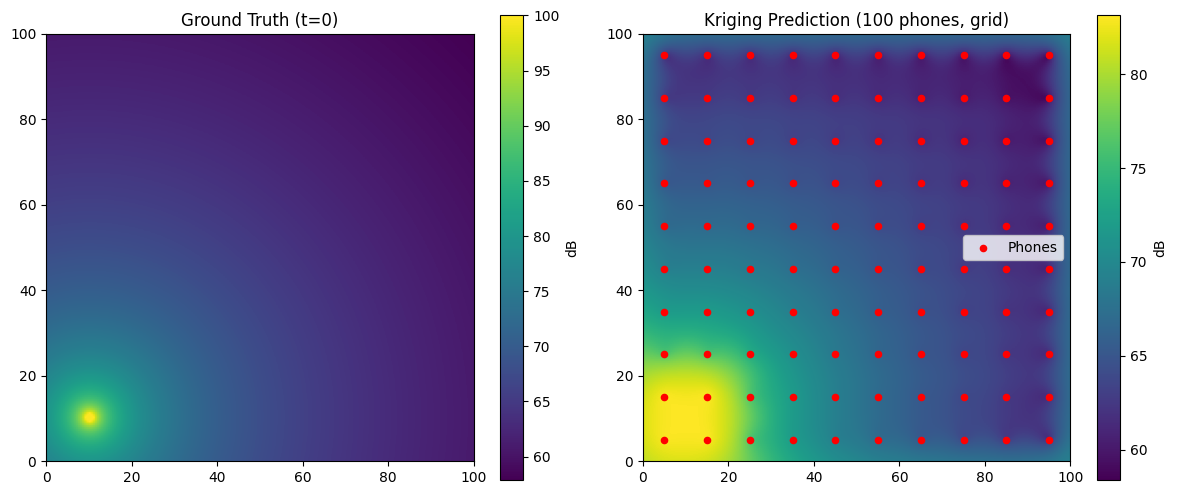

In [26]:
from scipy.spatial import distance_matrix
import numpy as np
import matplotlib.pyplot as plt

# Track benchmarking results
results = []

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]
        
        # 1. Run interpolation
        predicted_levels = kriging_model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"]
        )
        
        # 2. Compute Reconstruction Error (RMSE in dB across all time steps)
        rmse = np.sqrt(np.mean((predicted_levels - data["true_levels"]) ** 2))
        results.append({"count": count, "layout": layout, "rmse": rmse})
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {rmse:.2f} dB")


N_phones = 100
layout_type = "grid"
# 3. Visualize a specific reconstruction (Time step 0 for 20 clustered phones)
target_config = prepared_data[(N_phones, layout_type)]
pred_map = kriging_model.fit_predict(
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Reshape the flat 1D query array (M,) back to 2D grid (len(y), len(x))
grid_shape = (len(y), len(x))
reconstructed_2d = pred_map[0].reshape(grid_shape)
ground_truth_2d = target_config["true_levels"][0].reshape(grid_shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()])
axes[0].set_title("Ground Truth (t=0)")
plt.colorbar(im0, ax=axes[0], label="dB")

im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()])
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction ({N_phones} phones, {layout_type})")
axes[1].legend()
plt.colorbar(im1, ax=axes[1], label="dB")

plt.tight_layout()
plt.show()

Phones:   5 | Layout: random     | RMSE: 4.32 dB
Phones:   5 | Layout: grid       | RMSE: 4.25 dB
Phones:   5 | Layout: clustered  | RMSE: 6.44 dB
Phones:  10 | Layout: random     | RMSE: 3.58 dB
Phones:  10 | Layout: grid       | RMSE: 4.15 dB
Phones:  10 | Layout: clustered  | RMSE: 7.97 dB
Phones:  20 | Layout: random     | RMSE: 3.85 dB
Phones:  20 | Layout: grid       | RMSE: 2.74 dB
Phones:  20 | Layout: clustered  | RMSE: 5.50 dB
Phones:  50 | Layout: random     | RMSE: 2.96 dB
Phones:  50 | Layout: grid       | RMSE: 2.16 dB
Phones:  50 | Layout: clustered  | RMSE: 5.03 dB
Phones: 100 | Layout: random     | RMSE: 1.82 dB
Phones: 100 | Layout: grid       | RMSE: 1.14 dB
Phones: 100 | Layout: clustered  | RMSE: 4.39 dB


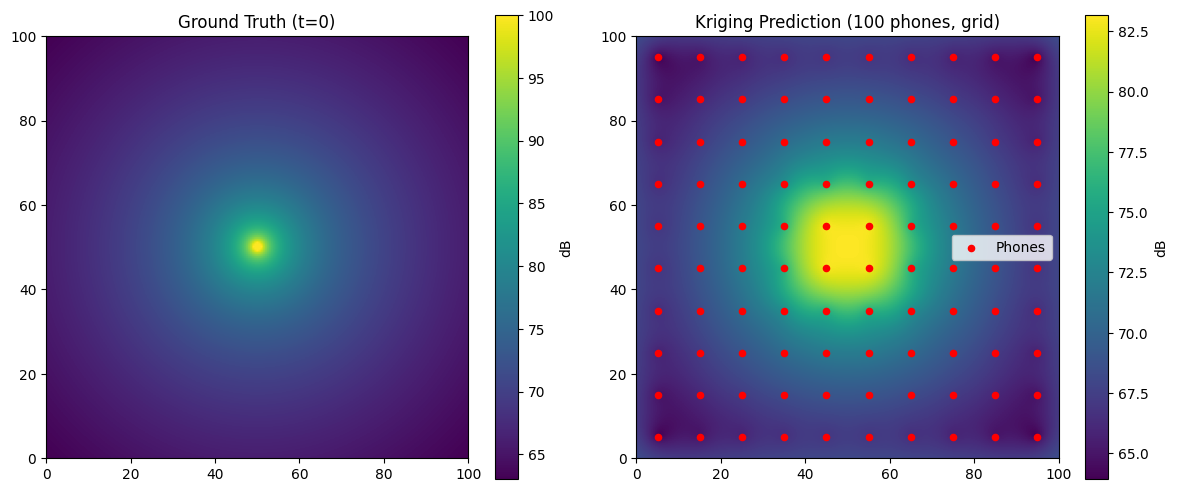

In [27]:
import numpy as np
import matplotlib.pyplot as plt

import point_source as sound_map
from extract_sound import prepare_interpolation_data


# 1. Load the sound maps and grid
sound_maps = sound_map.sound_maps
x = sound_map.x
y = sound_map.y

source_x = sound_map.source_x_positions
source_y = sound_map.source_y


# 2. Define phone configurations
phone_counts = [5, 10, 20, 50, 100]
layouts = ["random", "grid", "clustered"]


# 3. Prepare interpolation data (THIS WILL BE INPUT INTO THE INERPOLATION MODELS)
prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts
)



# Track benchmarking results
results = []

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]
        
        # 1. Run interpolation
        predicted_levels = kriging_model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"]
        )
        
        # 2. Compute Reconstruction Error (RMSE in dB across all time steps)
        rmse = np.sqrt(np.mean((predicted_levels - data["true_levels"]) ** 2))
        results.append({"count": count, "layout": layout, "rmse": rmse})
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {rmse:.2f} dB")


N_phones = 100
layout_type = "grid"
# 3. Visualize a specific reconstruction (Time step 0 for 20 clustered phones)
target_config = prepared_data[(N_phones, layout_type)]
pred_map = kriging_model.fit_predict(
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Reshape the flat 1D query array (M,) back to 2D grid (len(y), len(x))
grid_shape = (len(y), len(x))
reconstructed_2d = pred_map[0].reshape(grid_shape)
ground_truth_2d = target_config["true_levels"][0].reshape(grid_shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()])
axes[0].set_title("Ground Truth (t=0)")
plt.colorbar(im0, ax=axes[0], label="dB")

im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()])
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction ({N_phones} phones, {layout_type})")
axes[1].legend()
plt.colorbar(im1, ax=axes[1], label="dB")

plt.tight_layout()
plt.show()

Phones:   5 | Layout: random     | RMSE: 4.62 dB
Phones:   5 | Layout: grid       | RMSE: 4.91 dB
Phones:   5 | Layout: clustered  | RMSE: 11.59 dB
Phones:  10 | Layout: random     | RMSE: 5.00 dB
Phones:  10 | Layout: grid       | RMSE: 5.00 dB
Phones:  10 | Layout: clustered  | RMSE: 9.55 dB
Phones:  20 | Layout: random     | RMSE: 3.76 dB
Phones:  20 | Layout: grid       | RMSE: 3.05 dB
Phones:  20 | Layout: clustered  | RMSE: 12.92 dB
Phones:  50 | Layout: random     | RMSE: 3.10 dB
Phones:  50 | Layout: grid       | RMSE: 46.83 dB
Phones:  50 | Layout: clustered  | RMSE: 12.95 dB
Phones: 100 | Layout: random     | RMSE: 1.82 dB
Phones: 100 | Layout: grid       | RMSE: 1.40 dB
Phones: 100 | Layout: clustered  | RMSE: 9.03 dB


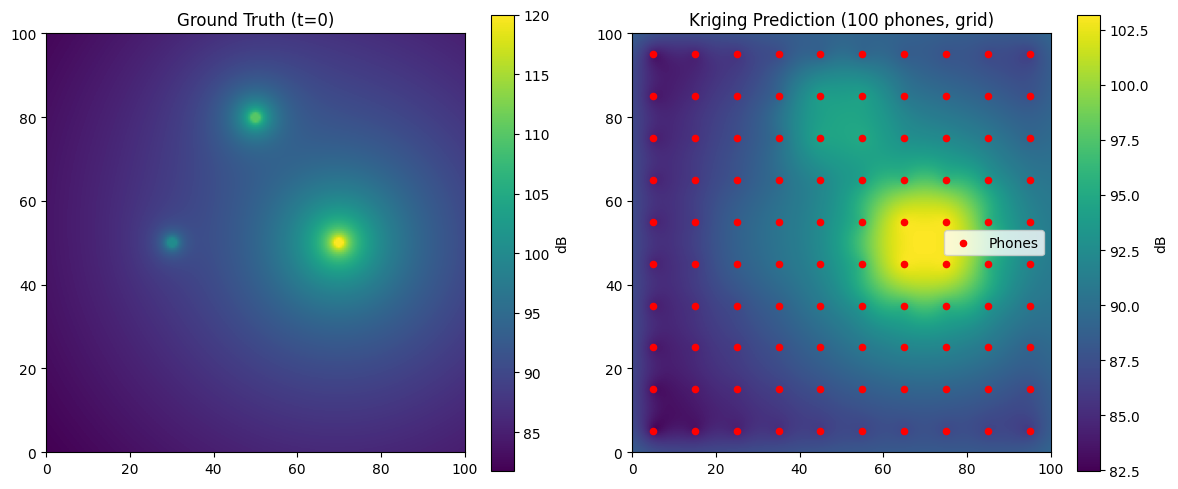

In [28]:
import numpy as np
import matplotlib.pyplot as plt

import multiple_point_sources as sound_map
from extract_sound import prepare_interpolation_data


# 1. Load the sound maps and grid
sound_maps = sound_map.sound_maps
x = sound_map.x
y = sound_map.y

source_x = sound_map.source_x_positions
source_y = sound_map.source_y


# 2. Define phone configurations
phone_counts = [5, 10, 20, 50, 100]
layouts = ["random", "grid", "clustered"]


# 3. Prepare interpolation data (THIS WILL BE INPUT INTO THE INERPOLATION MODELS)
prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts
)



# Track benchmarking results
results = []

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]
        
        # 1. Run interpolation
        predicted_levels = kriging_model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"]
        )
        
        # 2. Compute Reconstruction Error (RMSE in dB across all time steps)
        rmse = np.sqrt(np.mean((predicted_levels - data["true_levels"]) ** 2))
        results.append({"count": count, "layout": layout, "rmse": rmse})
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {rmse:.2f} dB")


N_phones = 100
layout_type = "grid"
# 3. Visualize a specific reconstruction (Time step 0 for 20 clustered phones)
target_config = prepared_data[(N_phones, layout_type)]
pred_map = kriging_model.fit_predict(
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Reshape the flat 1D query array (M,) back to 2D grid (len(y), len(x))
grid_shape = (len(y), len(x))
reconstructed_2d = pred_map[0].reshape(grid_shape)
ground_truth_2d = target_config["true_levels"][0].reshape(grid_shape)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()])
axes[0].set_title("Ground Truth (t=0)")
plt.colorbar(im0, ax=axes[0], label="dB")

im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()])
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction ({N_phones} phones, {layout_type})")
axes[1].legend()
plt.colorbar(im1, ax=axes[1], label="dB")

plt.tight_layout()
plt.show()